In [15]:
import numpy as np
import spectral.io.envi as envi
import spectral
import pandas as pd
import os
import matplotlib.pyplot as plt



In [16]:
input_path = '/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/351_1_240506-160920/capture/351_1_240506-160920.hdr'
output_dir = '/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing'
output_path = os.path.join(output_dir, 'espectros_swir_351_1.csv')


/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/.venv/lib/python3.11/site-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


ImageView object:
  Display bands       :  [0, 128.0, 255]
  Interpolation       :  <default>
  RGB data limits     :
    R: [np.float64(0.0), np.float64(4170.0)]
    G: [np.float64(2493.0), np.float64(15110.0)]
    B: [np.float64(2345.0), np.float64(3336.0)]

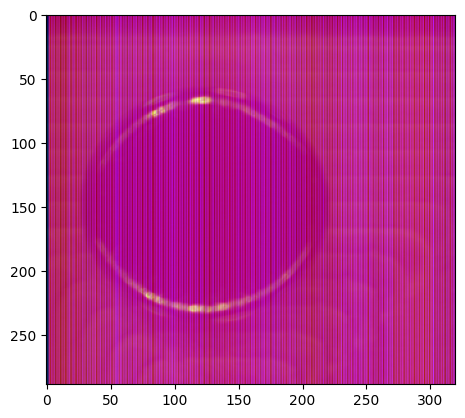

In [29]:
#Para ver a imagem og
img_spectral = envi.open(input_path)
img_array = np.array(img_spectral.load())

spectral.imshow(img_array)

In [18]:
print(f"Dimensões da imagem: {img_array.shape}")
print(f"Tipo de dados: {img_array.dtype}")
print(f"Valor mínimo: {img_array.min()}")
print(f"Valor máximo: {img_array.max()}")
print(f"Valor médio: {img_array.mean()}")

Dimensões da imagem: (289, 320, 256)
Tipo de dados: float32
Valor mínimo: 0.0
Valor máximo: 16091.0
Valor médio: 3566.56494140625


In [30]:
altura, largura, n_bandas = img_array.shape
n_amostras = altura * largura
espectros_matriz = img_array.reshape(n_amostras, n_bandas)
media_total = espectros_matriz.mean()
media_espectro = espectros_matriz.mean(axis=0)

print(f"Formato do array: {img_array.shape}")
print(f"Matriz final: {espectros_matriz.shape}")
print(f"n_amostras (pixels): {n_amostras}")
print(f"n_bandas espectrais: {n_bandas}")
print(f"Faixa de valores: [{espectros_matriz.min():.2f}, {espectros_matriz.max():.2f}]")
print(f"Média total da imagem HSI: {media_total:.2f}")



Formato do array: (289, 320, 256)
Matriz final: (92480, 256)
n_amostras (pixels): 92480
n_bandas espectrais: 256
Faixa de valores: [0.00, 16091.00]
Média total da imagem HSI: 3566.57


In [31]:
if img_array.max() > 1.0:
    img_array = (img_array - img_array.min()) / (img_array.max() - img_array.min())


In [32]:
altura, largura, n_bandas = img_array.shape
espectros_matriz = img_array.reshape(-1, n_bandas)

In [33]:
colunas = [f'Banda_{i}' for i in range(n_bandas)]
df_espectros = pd.DataFrame(espectros_matriz, columns=colunas)

In [34]:
df_espectros.head()

,Banda_0,Banda_1,Banda_2,Banda_3,Banda_4,Banda_5,Banda_6,Banda_7,Banda_8,Banda_9,...,Banda_246,Banda_247,Banda_248,Banda_249,Banda_250,Banda_251,Banda_252,Banda_253,Banda_254,Banda_255
0,0.000062,0.182027,0.178423,0.181219,0.181344,0.177304,0.178609,0.179044,0.172892,0.183767,...,0.170592,0.169101,0.167050,0.170406,0.171835,0.169474,0.174445,0.173451,0.176683,0.184016
1,0.000000,0.167112,0.169971,0.170033,0.167361,0.172208,0.164750,0.167547,0.164378,0.169598,...,0.153129,0.156920,0.151948,0.154061,0.161705,0.156609,0.152010,0.161643,0.164129,0.162948
2,0.180598,0.183457,0.180846,0.180784,0.176931,0.177553,0.176683,0.173762,0.173700,0.172830,...,0.158536,0.154993,0.166863,0.169039,0.162700,0.170468,0.168728,0.186440,0.173265,0.180287
3,0.164999,0.160276,0.147971,0.147847,0.149711,0.184140,0.154434,0.161581,0.159157,0.150208,...,0.141011,0.142440,0.140824,0.146355,0.143931,0.137903,0.140078,0.150830,0.144180,0.157106
4,0.181654,0.184575,0.179541,0.181095,0.181033,0.178609,0.176496,0.178050,0.181716,0.179666,...,0.162265,0.165621,0.160338,0.160089,0.163321,0.163632,0.164937,0.168293,0.175688,0.181033


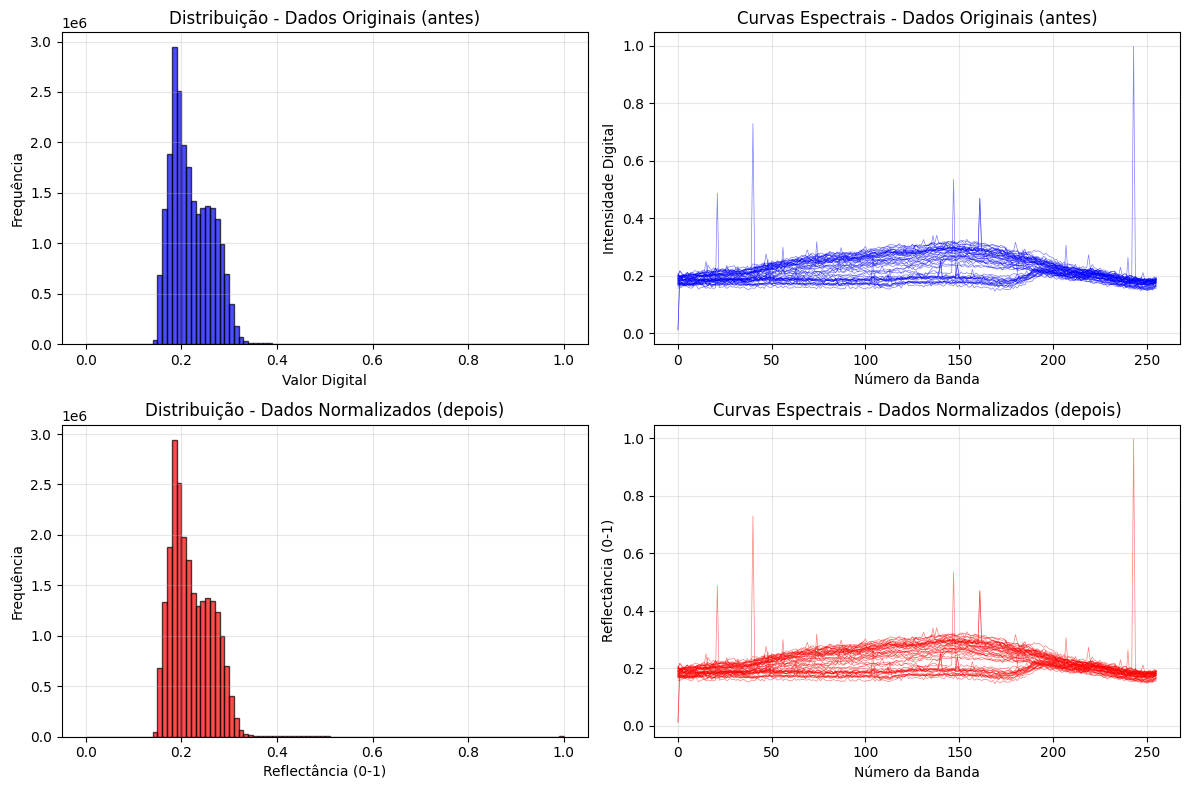

In [35]:
# AGORA fazer os gráficos ANTES e DEPOIS
altura, largura, n_bandas = img_array.shape
amostras_para_plot = min(50, altura * largura)
np.random.seed(42)
pixels_aleatorios = np.random.choice(altura * largura, amostras_para_plot, replace=False)

# Preparar matrizes para plotting
espectros_matriz_original = img_array.reshape(-1, n_bandas)
espectros_matriz_normalized = img_array_normalized.reshape(-1, n_bandas)

plt.figure(figsize=(12, 8))


plt.subplot(2, 2, 1)
plt.hist(img_array.flatten(), bins=100, alpha=0.7, color='blue', edgecolor='black')
plt.title('Distribuição - Dados Originais (antes)')
plt.xlabel('Valor Digital')
plt.ylabel('Frequência')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 2)
for idx in pixels_aleatorios:
    plt.plot(espectros_matriz_original[idx, :], alpha=0.5, linewidth=0.5, color='blue')
plt.title('Curvas Espectrais - Dados Originais (antes)')
plt.xlabel('Número da Banda')
plt.ylabel('Intensidade Digital')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 3)
plt.hist(img_array_normalized.flatten(), bins=100, alpha=0.7, color='red', edgecolor='black')
plt.title('Distribuição - Dados Normalizados (depois)')
plt.xlabel('Reflectância (0-1)')
plt.ylabel('Frequência')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 4)
for idx in pixels_aleatorios:
    plt.plot(espectros_matriz_normalized[idx, :], alpha=0.5, linewidth=0.5, color='red')
plt.title('Curvas Espectrais - Dados Normalizados (depois)')
plt.xlabel('Número da Banda')
plt.ylabel('Reflectância (0-1)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
output_path_original = os.path.join(output_dir, 'espectros_originais_normalizados.csv')
df_espectros.to_csv(output_path_original, index=False)
print(f"✅ Dados originais salvos em: {output_path_original}")

/tmp/ipykernel_6224/2822438566.py:36: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  roi = img * mask3d


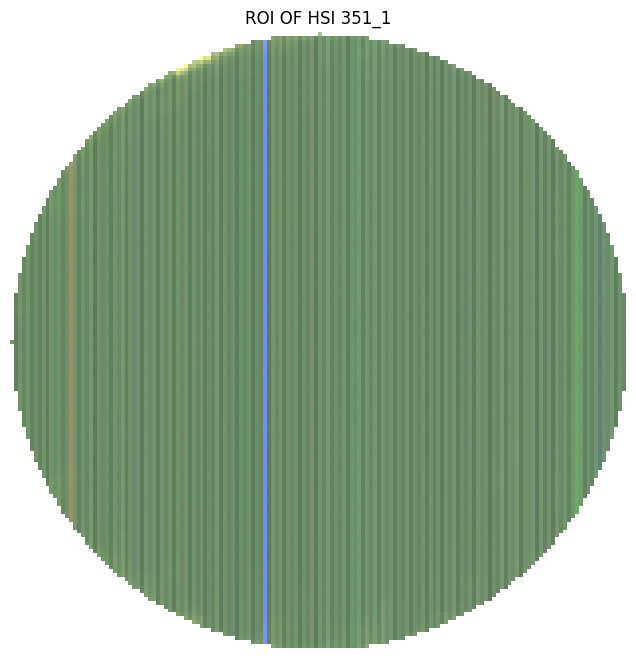

In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import spectral

# Carregar HSI como numpy array
img = spectral.open_image(
    "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/351_1_240506-160920/capture/351_1_240506-160920.hdr"
).load()

# Criar imagem RGB para visualização
rgb = spectral.get_rgb(img, [50, 30, 10])

gray = cv2.cvtColor((rgb * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
gray = cv2.GaussianBlur(gray, (7, 7), 2)

circles = cv2.HoughCircles(
    gray,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=100,
    param1=100,
    param2=30,
    minRadius=50,
    maxRadius=200
)

mask = np.zeros(gray.shape, dtype=np.uint8)

if circles is not None:
    x, y, r = circles[0][0]
    cv2.circle(mask, (int(x), int(y)), int(r), 1, thickness=-1)

mask3d = np.repeat(mask[:, :, np.newaxis], img.shape[2], axis=2)

roi = img * mask3d

roi_rgb = spectral.get_rgb(roi, [50, 30, 10])
roi_rgb_norm = roi_rgb / roi_rgb.max()

# Obter dimensões da imagem
altura, largura, n_bandas = img.shape
img_array = img

# Número total de pixels (amostras)
n_amostras = altura * largura

# Transformar a imagem em matriz 2D (pixels x bandas)
espectros_matriz = img.reshape(n_amostras, n_bandas)

# Média global da imagem
media_total = espectros_matriz.mean()

# RECORTAR APENAS A REGIÃO DO ROI
if circles is not None:
    x, y, r = circles[0][0]
    x, y, r = int(x), int(y), int(r)
    
    # Definir os limites do crop
    x_min = max(0, x - r)
    x_max = min(largura, x + r)
    y_min = max(0, y - r)
    y_max = min(altura, y + r)
    
    # Recortar a imagem RGB e a máscara
    roi_rgb_cropped = roi_rgb_norm[y_min:y_max, x_min:x_max]
    mask_cropped = mask[y_min:y_max, x_min:x_max]
    
    # Criar versão RGBA para transparência
    roi_rgba = np.zeros((roi_rgb_cropped.shape[0], roi_rgb_cropped.shape[1], 4))
    roi_rgba[:, :, :3] = roi_rgb_cropped  # RGB
    roi_rgba[:, :, 3] = mask_cropped      # Alpha (transparência)

plt.figure(figsize=(8, 8))
plt.imshow(roi_rgba)
plt.title("ROI OF HSI 351_1")
plt.xlabel("Rows")
plt.ylabel("Samples")
plt.axis('off')  # Remove os eixos

plt.savefig("roi_hsi_351_1.png", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [10]:
import numpy as np
import cv2
import spectral
import pandas as pd

# ==============================================================================
# 1. CARREGAMENTO DA IMAGEM HSI
# ==============================================================================

img = spectral.open_image(
    "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/351_1_240506-160920/capture/351_1_240506-160920.hdr"
).load()

print(f"Imagem carregada: {img.shape}")

# ==============================================================================
# 2. DETECÇÃO AUTOMÁTICA DO ROI CIRCULAR
# ==============================================================================

# Criar imagem RGB para detecção do círculo
rgb = spectral.get_rgb(img, [50, 30, 10])

# Converter para escala de cinza e aplicar blur
gray = cv2.cvtColor((rgb * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
gray = cv2.GaussianBlur(gray, (7, 7), 2)

# Detectar círculo usando Hough Transform
circles = cv2.HoughCircles(
    gray,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=100,
    param1=100,
    param2=30,
    minRadius=50,
    maxRadius=200
)

# Criar máscara circular
mask = np.zeros(gray.shape, dtype=np.uint8)

if circles is not None:
    x, y, r = circles[0][0]
    cv2.circle(mask, (int(x), int(y)), int(r), 1, thickness=-1)
    print(f"ROI detectado: centro=({int(x)}, {int(y)}), raio={int(r)}")

# ==============================================================================
# 3. RECORTE E REMOÇÃO DO FUNDO
# ==============================================================================

altura, largura, n_bandas = img.shape

if circles is not None:
    x, y, r = circles[0][0]
    x, y, r = int(x), int(y), int(r)
    
    # Definir os limites do crop
    x_min = max(0, x - r)
    x_max = min(largura, x + r)
    y_min = max(0, y - r)
    y_max = min(altura, y + r)
    
    # Recortar a imagem
    roi_cropped = img[y_min:y_max, x_min:x_max, :]
    mask_cropped = mask[y_min:y_max, x_min:x_max]
    
    print(f"ROI recortado: {roi_cropped.shape}")

# ==============================================================================
# 4. CÁLCULO DE MÉTRICAS (SNR, VARIÂNCIA)
# ==============================================================================

# Transformar ROI em matriz 2D (pixels x bandas)
altura_crop, largura_crop, _ = roi_cropped.shape
roi_reshaped = roi_cropped.reshape(-1, n_bandas)

# Extrair apenas pixels válidos (dentro do círculo)
mask_flat = mask_cropped.flatten()
roi_pixels = roi_reshaped[mask_flat > 0]

print(f"Pixels válidos no ROI: {roi_pixels.shape[0]}")

# Calcular métricas por banda
snr_list = []
variance_list = []
mean_list = []

for banda in range(n_bandas):
    banda_data = roi_pixels[:, banda]
    
    # Média e variância
    media = np.mean(banda_data)
    variancia = np.var(banda_data)
    
    # SNR (Signal-to-Noise Ratio)
    std = np.std(banda_data)
    snr = media / std if std > 0 else 0
    
    snr_list.append(snr)
    variance_list.append(variancia)
    mean_list.append(media)

snr_array = np.array(snr_list)
variance_array = np.array(variance_list)
mean_array = np.array(mean_list)

# ==============================================================================
# 5. REMOÇÃO DE BANDAS RUIDOSAS
# ==============================================================================

# Critério 1: SNR muito baixo (abaixo do percentil 15)
snr_threshold = np.percentile(snr_array, 15)
bandas_baixo_snr = np.where(snr_array < snr_threshold)[0]

# Critério 2: Variância muito baixa (bandas quase constantes - ruído)
var_threshold = np.percentile(variance_array, 5)
bandas_baixa_variancia = np.where(variance_array < var_threshold)[0]

# Critério 3: Bandas nas extremidades espectrais (primeiras e últimas)
n_remover_extremos = 15
bandas_inicio = np.arange(0, n_remover_extremos)
bandas_fim = np.arange(n_bandas - n_remover_extremos, n_bandas)

# Combinar todas as bandas a serem removidas
bandas_remover = np.unique(np.concatenate([
    bandas_baixo_snr,
    bandas_baixa_variancia,
    bandas_inicio,
    bandas_fim
]))

# Bandas a manter
bandas_manter = np.setdiff1d(np.arange(n_bandas), bandas_remover)

print(f"\n{'='*60}")
print("ANÁLISE DE BANDAS RUIDOSAS")
print(f"{'='*60}")
print(f"Bandas originais: {n_bandas}")
print(f"Bandas com SNR baixo (< {snr_threshold:.2f}): {len(bandas_baixo_snr)}")
print(f"Bandas com variância baixa (< {var_threshold:.2f}): {len(bandas_baixa_variancia)}")
print(f"Bandas removidas nas extremidades: {len(bandas_inicio) + len(bandas_fim)}")
print(f"\nTotal de bandas removidas: {len(bandas_remover)}")
print(f"Bandas restantes: {len(bandas_manter)}")
print(f"Percentual mantido: {(len(bandas_manter)/n_bandas)*100:.1f}%")
print(f"{'='*60}\n")

# Aplicar filtragem - remover bandas ruidosas
roi_filtrado = roi_cropped[:, :, bandas_manter]

print(f"Dimensões após filtragem: {roi_filtrado.shape}")

# ==============================================================================
# 6. SALVAMENTO EM CSV (APENAS PIXELS)
# ==============================================================================

# Transformar ROI filtrado em matriz 2D
altura_final, largura_final, n_bandas_final = roi_filtrado.shape
roi_filtrado_reshaped = roi_filtrado.reshape(-1, n_bandas_final)

# Extrair apenas pixels válidos
roi_filtrado_pixels = roi_filtrado_reshaped[mask_flat > 0]

# Criar DataFrame APENAS com os valores espectrais
colunas_bandas = [f'banda_{i}' for i in bandas_manter]
df_roi_filtrado = pd.DataFrame(roi_filtrado_pixels, columns=colunas_bandas)

# Salvar em CSV
df_roi_filtrado.to_csv('roi_filtrado_final.csv', index=False)

print(f"\n{'='*60}")
print("ARQUIVO SALVO")
print(f"{'='*60}")
print(f"✓ roi_filtrado_final.csv")
print(f"  Dimensões: {df_roi_filtrado.shape[0]} pixels × {df_roi_filtrado.shape[1]} bandas")
print(f"  Bandas espectrais: {n_bandas_final}")
print(f"{'='*60}\n")

Imagem carregada: (289, 320, 256)
ROI detectado: centro=(120, 148), raio=78
ROI recortado: (156, 156, 256)
Pixels válidos no ROI: 19107

ANÁLISE DE BANDAS RUIDOSAS
Bandas originais: 256
Bandas com SNR baixo (< 10.31): 39
Bandas com variância baixa (< 37281.18): 13
Bandas removidas nas extremidades: 30

Total de bandas removidas: 72
Bandas restantes: 184
Percentual mantido: 71.9%

Dimensões após filtragem: (156, 156, 184)

ARQUIVO SALVO
✓ roi_filtrado_final.csv
  Dimensões: 19107 pixels × 184 bandas
  Bandas espectrais: 184

